У меня вариант номер 6

| x   | 1   | 4   | 7    | 10   | 13   | 16   |
| --- | --- | --- | ---- | ---- | ---- | ---- |
| y   | 3.0 | 7.6 | 11.2 | 13.8 | 17.1 | 19.5 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = np.array([1, 4, 7, 10, 13, 16], dtype=float)
y = np.array([3.0, 7.6, 11.2, 13.8, 17.1, 19.5])

# Часть 1. Линейная функция

In [2]:
def fit_linear(x, y):
    """y = a*x + b, система (7)"""
    n = len(x)
    A = np.array([[np.sum(x**2), np.sum(x)],
                  [np.sum(x),    n]])
    B = np.array([np.sum(x * y), np.sum(y)])
    a, b = np.linalg.solve(A, B)
    return a, b

a1, b1 = fit_linear(x, y)
f1 = lambda t: a1 * t + b1
print(f"Линейная: y = {a1:.2f}x + {b1:.2f}")

Линейная: y = 1.08x + 2.84


# Часть 2. Степенная функция

In [3]:
def fit_power(x, y):
    """ln y = a*ln x + ln β"""
    a, b = fit_linear(np.log(x), np.log(y))
    return a, np.exp(b)

a2, beta2 = fit_power(x, y)
f2 = lambda t: beta2 * t**a2
print(f"Степенная: y = {beta2:.2f} * x^{a2:.2f}")

Степенная: y = 2.99 * x^0.67


# Часть 3. Показательная функция

In [4]:
def fit_exp(x, y):
    """ln y = a*x + ln β"""
    a, b = fit_linear(x, np.log(y))
    return a, np.exp(b)

a3, beta3 = fit_exp(x, y)
f3 = lambda t: beta3 * np.exp(a3 * t)
print(f"Показательная: y = {beta3:.2f} * e^({a3:.2f}x)")

Показательная: y = 3.89 * e^(0.11x)


# Часть 4. Квадратичная функция

In [5]:
def fit_quadratic(x, y):
    """y = a*x^2 + b*x + c, система (15)"""
    n = len(x)
    A = np.array([[np.sum(x**4), np.sum(x**3), np.sum(x**2)],
                  [np.sum(x**3), np.sum(x**2), np.sum(x)],
                  [np.sum(x**2), np.sum(x),    n]])
    B = np.array([np.sum(x**2 * y), np.sum(x * y), np.sum(y)])
    return np.linalg.solve(A, B)

a4, b4, c4 = fit_quadratic(x, y)
f4 = lambda t: a4 * t**2 + b4 * t + c4
print(f"Квадратичная: y = {a4:.2f}x^2 + {b4:.2f}x + {c4:.2f}")

Квадратичная: y = -0.02x^2 + 1.49x + 1.72


# Часть 5. Графики полученных функций

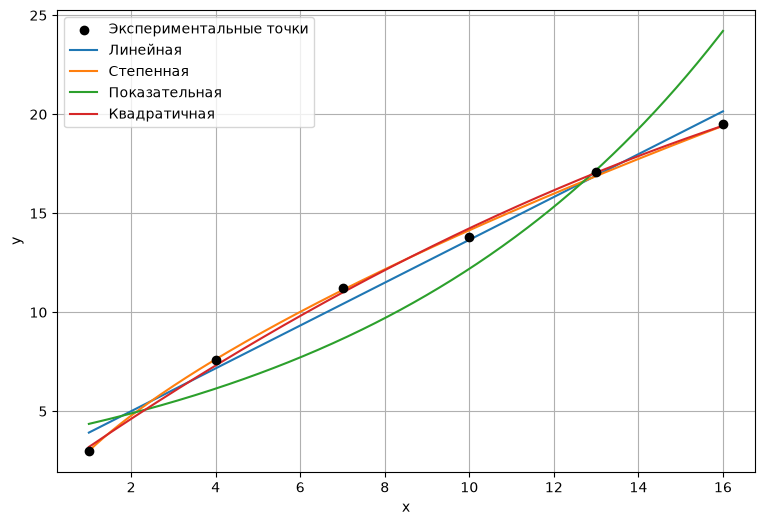

In [6]:
t = np.linspace(x.min(), x.max(), 300)
plt.figure(figsize=(9, 6))
plt.scatter(x, y, color='black', zorder=5, label='Экспериментальные точки')
for f, name in [(f1, 'Линейная'), (f2, 'Степенная'),
                (f3, 'Показательная'), (f4, 'Квадратичная')]:
    plt.plot(t, f(t), label=name)
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True); plt.legend()
plt.show()

# Часть 6. Сравнение

In [7]:
funcs = {'линейная': f1, 'степенная': f2, 'показательная': f3, 'квадратичная': f4}

table = pd.DataFrame({'x': x, 'y': y, **{k: f(x) for k, f in funcs.items()}}).round(2)
print(table)

L = pd.Series({k: np.sum((y - f(x))**2) for k, f in funcs.items()})
print(L.round(2))
print('Лучшая:', L.idxmin())

      x     y  линейная  степенная  показательная  квадратичная
0   1.0   3.0      3.92       2.99           4.36          3.19
1   4.0   7.6      7.16       7.62           6.14          7.31
2   7.0  11.2     10.41      11.12           8.65         10.99
3  10.0  13.8     13.66      14.14          12.19         14.24
4  13.0  17.1     16.90      16.88          17.18         17.05
5  16.0  19.5     20.15      19.41          24.21         19.42
линейная          2.14
степенная         0.18
показательная    35.20
квадратичная      0.36
dtype: float64
Лучшая: степенная
